        city                host_type  num_hosts  total_listings  pct_listings
0  Barcelona  Multi-listing Host (>1)       1344           10291     83.591910
1  Barcelona  Single-listing Host (1)       2020            2020     16.408090
2     Madrid  Multi-listing Host (>1)       2193           14327     76.940014
3     Madrid  Single-listing Host (1)       4294            4294     23.059986


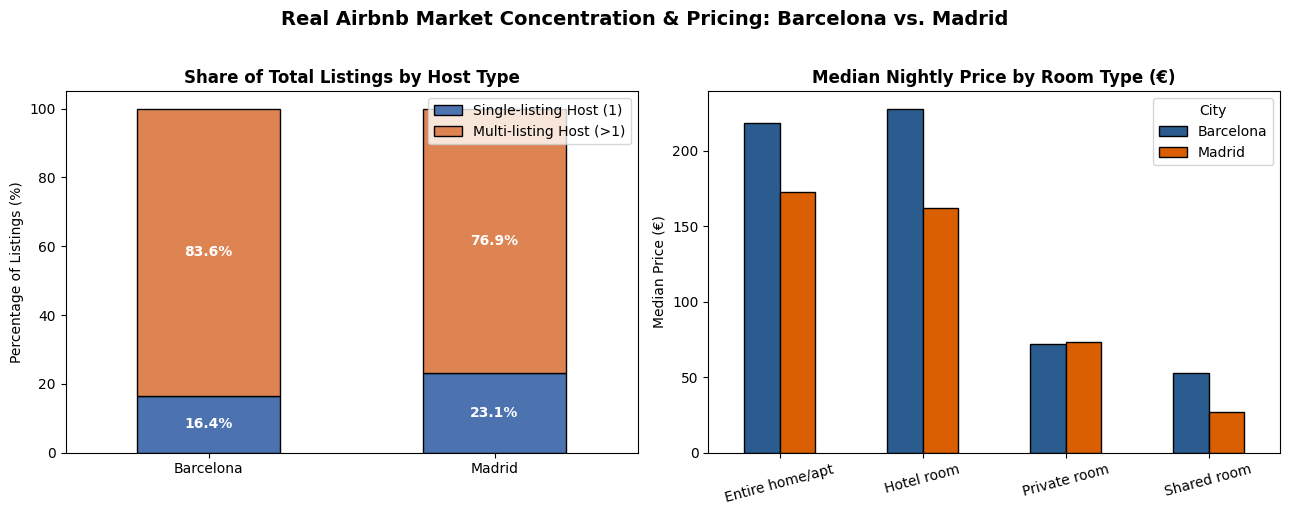

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("reports", exist_ok=True)

url_bcn = "https://data.insideairbnb.com/spain/catalonia/barcelona/2026-09-17/data/listings.csv.gz"
url_mad = "https://data.insideairbnb.com/spain/comunidad-de-madrid/madrid/2026-09-17/data/listings.csv.gz"

!wget -q -O data/barcelona_listings.csv.gz "{url_bcn}"
!wget -q -O data/madrid_listings.csv.gz "{url_mad}"

cols = ["id", "host_id", "neighbourhood_group_cleansed", "room_type", "price", "availability_365", "number_of_reviews"]
bcn = pd.read_csv("data/barcelona_listings.csv.gz", usecols=cols)
mad = pd.read_csv("data/madrid_listings.csv.gz", usecols=cols)

bcn["city"] = "Barcelona"
mad["city"] = "Madrid"
df = pd.concat([bcn, mad], ignore_index=True)

df["price_clean"] = df["price"].astype(str).str.replace(r"[\$,]", "", regex=True)
df["price_clean"] = pd.to_numeric(df["price_clean"], errors="coerce")
df = df.dropna(subset=["price_clean"])
df = df[(df["price_clean"] > 0) & (df["price_clean"] <= 1000)]

host_counts = df.groupby(["city", "host_id"])["id"].count().reset_index(name="listings_per_host")
host_counts["host_type"] = np.where(host_counts["listings_per_host"] > 1, "Multi-listing Host (>1)", "Single-listing Host (1)")

summary = host_counts.groupby(["city", "host_type"]).agg(
    num_hosts=("host_id", "count"),
    total_listings=("listings_per_host", "sum")
).reset_index()
summary["pct_listings"] = summary["total_listings"] / summary.groupby("city")["total_listings"].transform("sum") * 100
print(summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

pivot_pct = summary.pivot(index="city", columns="host_type", values="pct_listings")
pivot_pct[["Single-listing Host (1)", "Multi-listing Host (>1)"]].plot(
    kind="bar", stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452"], edgecolor="black"
)
axes[0].set_title("Share of Total Listings by Host Type", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Percentage of Listings (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")

price_room = df.groupby(["room_type", "city"])["price_clean"].median().unstack()
price_room.plot(kind="bar", ax=axes[1], color=["#2B5C8F", "#D95F02"], edgecolor="black")
axes[1].set_title("Median Nightly Price by Room Type (€)", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Median Price (€)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="City")

plt.suptitle("Real Airbnb Market Concentration & Pricing: Barcelona vs. Madrid", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("reports/graph3.png", dpi=300, bbox_inches="tight")
plt.show()